In [64]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [65]:


# create the state column
def combine_state_data(folder):
    csv_files = sorted(Path(folder).rglob("*sort.csv"))
    if not csv_files:
        raise FileNotFoundError(f"No CSV files found in: {folder}")

    dataframes = []

    for file in csv_files:
        df = pd.read_csv(file)
        df["State"] = df.iloc[0,0]
        df = df.iloc[1:].copy()
        dataframes.append(df)

    return pd.concat(dataframes, ignore_index=True)

In [71]:
from numpy import int64
all_states = combine_state_data("state_crash_data")
all_states = all_states.iloc[:, :8]
all_states["# Motor Vehicle Deaths"] = (
    all_states["# Motor Vehicle Deaths"].str.replace(",", "")
    )
all_states["# Motor Vehicle Deaths"] = (all_states["# Motor Vehicle Deaths"]).astype("Int64")

all_states.to_csv("combined_data/all_states.csv", index=False)

original_deaths = all_states["# Motor Vehicle Deaths"].copy()

# Remove thousands separators and convert to numbers.
all_states["# Motor Vehicle Deaths"] = pd.to_numeric(
    original_deaths
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.strip(),
    errors="coerce"
)

In [72]:
all_states.sort_values(
    by="# Motor Vehicle Deaths",
    ascending=False
).head(5)

,County,# Motor Vehicle Deaths,County Value**,Error Margin,Hispanic (all races),Non-Hispanic Black,Non-Hispanic White,State
175,Los Angeles,6701,10.0,9-10,10.0,20.0,9.0,California
74,Maricopa,4108,13.0,13-13,14.0,18.0,12.0,Arizona
2580,Harris,3896,12.0,11-12,11.0,17.0,12.0,Texas
567,Cook,2939,8.0,8-8,7.0,15.0,6.0,Illinois
192,San Bernardino,2534,17.0,16-17,15.0,25.0,19.0,California


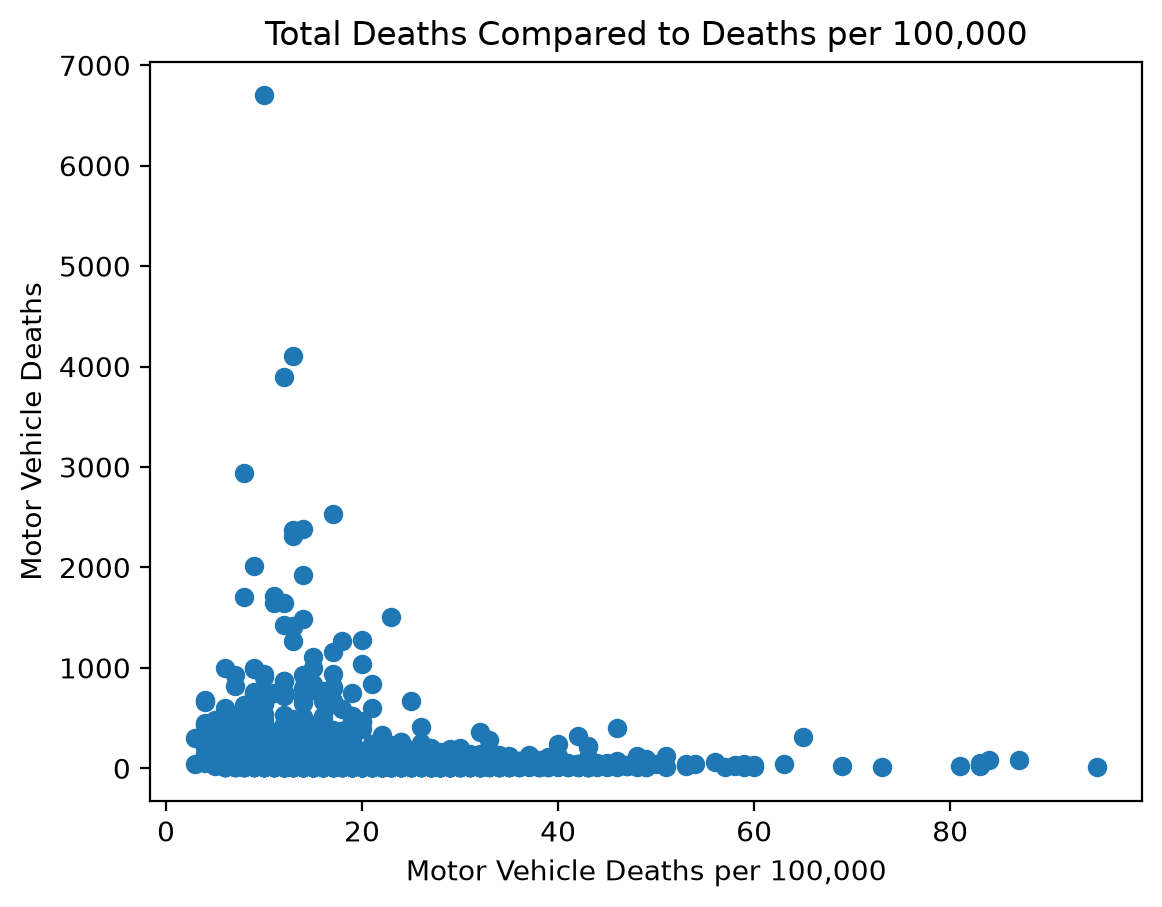

In [73]:
plt.scatter(all_states["County Value**"], all_states["# Motor Vehicle Deaths"])
plt.xlabel("Motor Vehicle Deaths per 100,000")
plt.ylabel("Motor Vehicle Deaths")
plt.title("Total Deaths Compared to Deaths per 100,000")
plt.show()

In [74]:
# Requires running uv add 
population = pd.read_excel("/Users/Tyrannosaurus/Desktop/School/STAT_386/data_acquisition/population_data/co-est2025-pop.xlsx")

name_column = (
    "table with row headers in column A and column headers "
    "in rows 3 through 4 (leading dots indicate sub-parts)"
)

# Extract everything after the comma into a state column
population["State"] = (
    population[name_column]
    .str.extract(r",\s*(.+)$", expand=False)
    .str.strip()
)

# Clean the county name
population["County"] = (
    population[name_column]
    .str.replace(r"^\.", "", regex=True)
    .str.replace(r",.*$", "", regex=True)
    .str.replace(r"\s+County$", "", regex=True)
    .str.strip()
)

# Remove the unwanted rows
population = population.drop([0, 1, 2, 3], axis=0)

#keep only the most recent population estimate and the county
population = population.drop(
    ['table with row headers in column A and column headers in rows 3 through 4 (leading dots indicate sub-parts)',
       'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4',
       'Unnamed: 5', 'Unnamed: 6'], 
    axis = 1
    )
population = population.rename(
    columns={"Unnamed: 7": "2025 population estimates"}
)


In [75]:
from posixpath import join
# final data merge add the population data to the combined crash data

combined_data = all_states.merge(
    population[["County", "State", "2025 population estimates"]],
    on=["County", "State"],
    how="left",
    validate="many_to_one",
    indicator=True
)

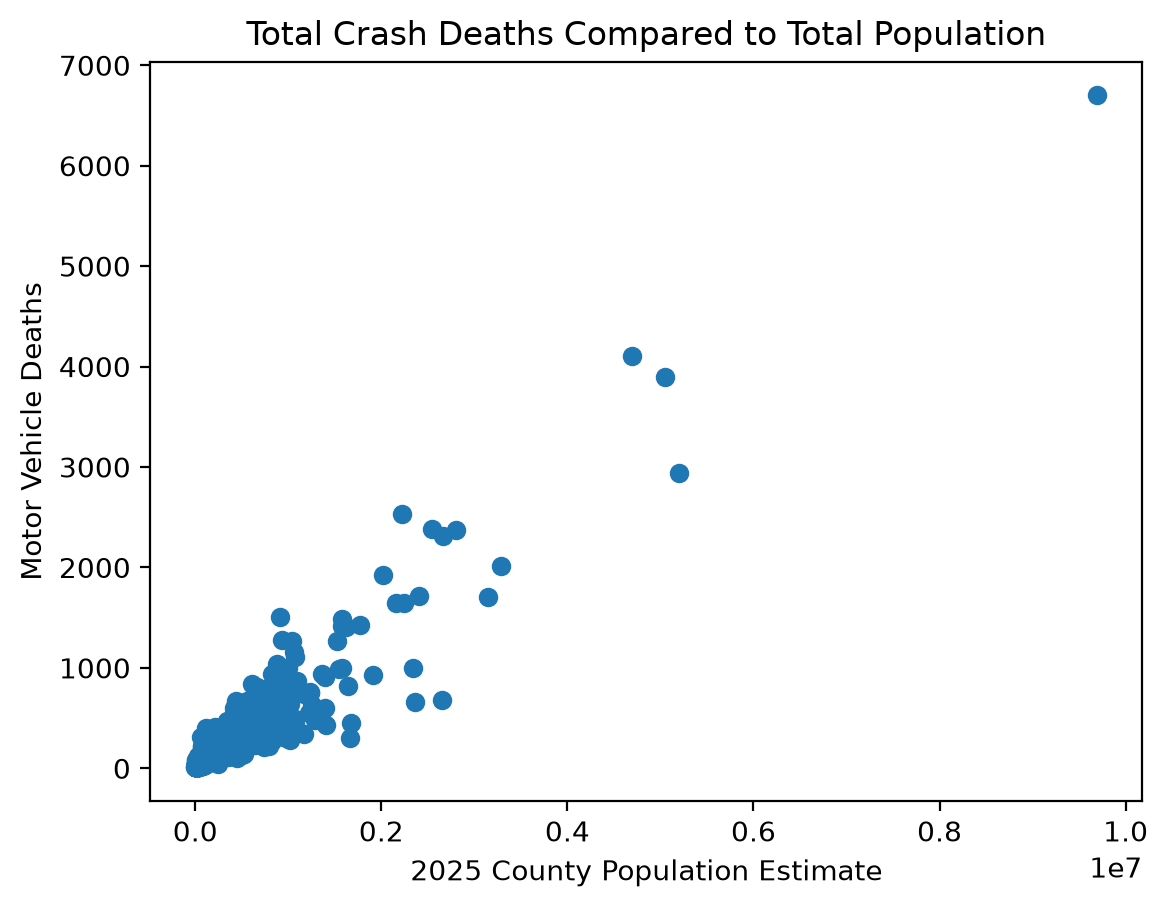

In [76]:
plt.scatter(combined_data["2025 population estimates"], combined_data["# Motor Vehicle Deaths"])
plt.xlabel("2025 County Population Estimate")
plt.ylabel("Motor Vehicle Deaths")
plt.title("Total Crash Deaths Compared to Total Population")
plt.show()

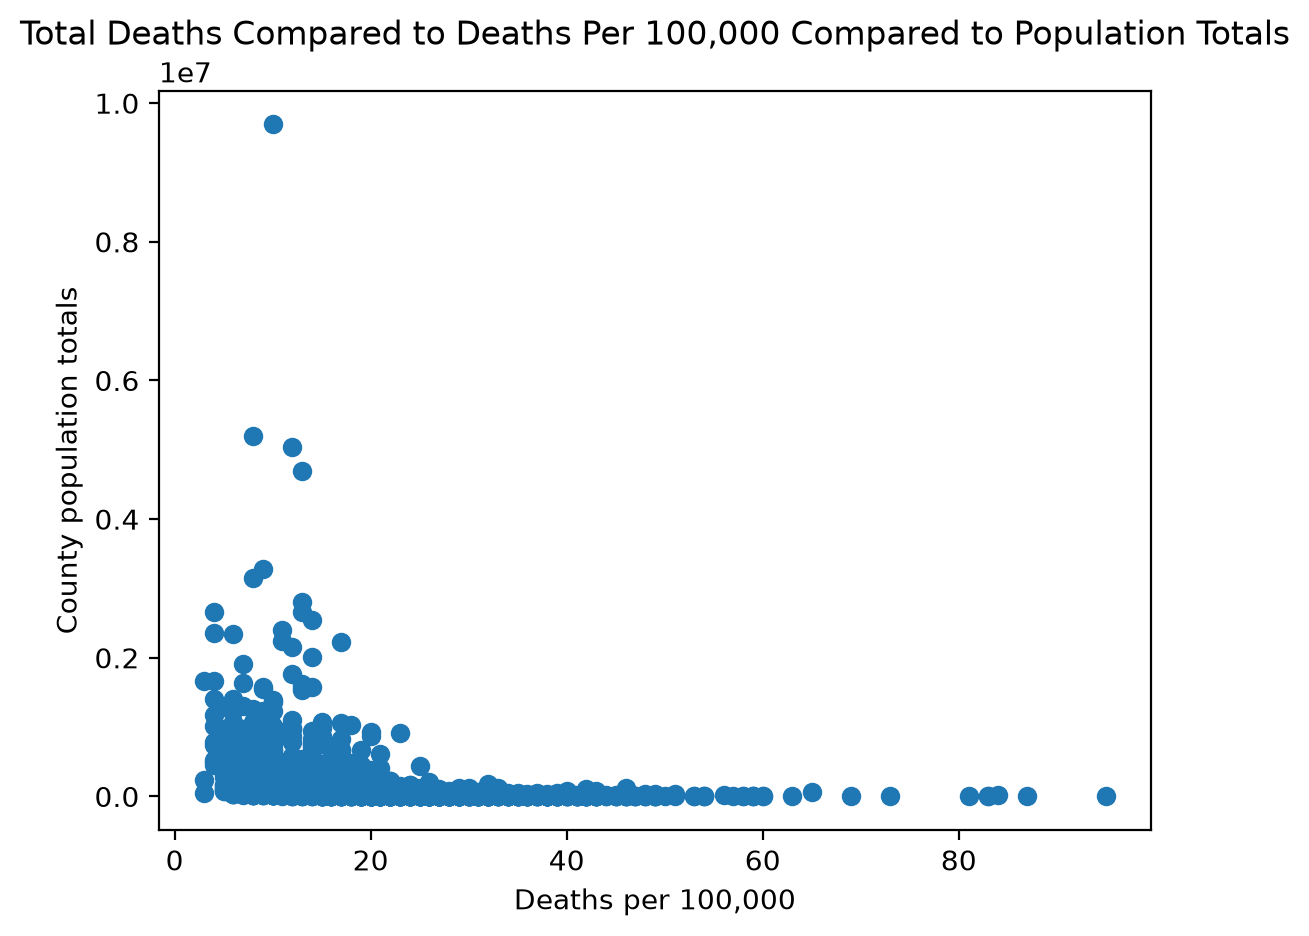

In [77]:
plt.scatter(combined_data["County Value**"], combined_data["2025 population estimates"])
plt.xlabel("Deaths per 100,000")
plt.ylabel("County population totals")
plt.title("Total Deaths Compared to Deaths Per 100,000 Compared to Population Totals")
plt.show()